## Calculate stellar properties 

In particular, we can compute the minimum mass and star velocity, as well as the resolution required for the wind injection

In [1]:
import numpy as np
import h5py
import astropy.units as u
import astropy.constants as const

import matplotlib.pyplot as plt

import matplotlib.colors as mcolors
import matplotlib.cm as cm

In [2]:
def stand_off_radius(Mdot, vw, rho0, vstar, P0, adi_idx, B):
    '''stand-off radius / pc'''
    cism2 = (adi_idx * P0 / rho0).to(u.km**2/u.s**2)
    valf2 = (B**2 / (const.mu0.si * rho0)).to(u.km**2/u.s**2)

    return (np.sqrt((Mdot * vw) / (4 * np.pi * rho0 * (vstar**2 + cism2 + valf2)))).to(u.pc)

def grid_resolution(xmin, xmax, amr_lvl_max):
    return np.abs(xmax - xmin) / (2**(amr_lvl_max - 1) * 8)

env_params = {
    "ISM":{
        "n0":None,
        "rho0":2e-25,
        "T0":1e4,
        "P0":None,
        "B":1e-6,
        "xmax":100,
    },
    "CMZ":{
        "n0":None,
        "rho0":1e-23,
        "T0":None,
        "P0":1e7,
        "B":1e-5,
        "xmax":7.5,
    },
    "X3A":{
        "n0":5e4,
        "rho0":None,
        "T0":7000,
        "P0":None,
        "B":0.0,
        "xmax":0.05,
    },
    "WR102":{
        "n0":None,
        "rho0":1e-23,
        "T0":None,
        "P0":1e7,
        "B":1.2e-5,
        "xmax":7.5,
    },
}

In [3]:
# set the environmental condition
env = "ISM"
env_param_dict = env_params[env]

In [15]:
# parameters we know at priori

# environment parameters

if env_param_dict["n0"] != None:
    rho0 = 0.61 * const.m_p.cgs * env_param_dict["n0"] * u.cm**-3
else:
    rho0 = env_param_dict["rho0"] * (u.g / u.cm**3)

T0 = env_param_dict["T0"]
P0 = env_param_dict["P0"]  # P0 / KB

adi_idx = 5/3

if T0 != None:
    T0 = T0 * u.K
    # calculate ambienmmt pressure from temperature and density
    cs = np.sqrt(adi_idx * const.k_B.cgs * T0 / (const.m_p.cgs))
    print(cs.to(u.km/u.s))
    P0 = rho0 * cs**2 / adi_idx
elif P0 != None:
    P0 = (P0 * (u.K / u.cm**3)) * const.k_B.cgs  # convert back to P0 units
    # calculate temperature from pressure and densitu
    cs = np.sqrt(adi_idx * P0 / rho0)
    T0 = (cs**2 * const.m_p.cgs / (adi_idx * const.k_B.cgs)).to(u.K)

B = env_param_dict["B"] * (u.G)

print(f"density : {rho0:.3e}")
print(f"temperature : {T0:.3e}")
print(f"Pressure : {P0:.3e}")
print(f"B : {B:.1e}")

# print((np.sqrt(B.value**2 / (4 * np.pi * rho0.value)) * (u.cm/u.s)).to(u.km / u.s))

xmin = 0
xmax = env_param_dict["xmax"] * u.pc
print(f"Size of a single block: [{xmin:1f}, {xmax:.1f}] pc")

11.729165753741977 km / s
density : 2.000e-25 g / cm3
temperature : 1.000e+04 K
Pressure : 1.651e-13 erg / cm3
B : 1.0e-06 G
6.307831305050401 km / s
Size of a single block: [0.000000, 100.0 pc] pc


for different stellar masses, get the mass loss rate and wind velocity by reading the table from `data/source-stellar.dat` and performing interpolation if needed

In [5]:
# mass_list = [10, 15, 20, 25, 30, 45, 60]
mass_arr = np.arange(9, 61, 1) * (u.M_sun)

assert min(mass_arr) >= 9 * u.M_sun  # since the datafile only has from solarmass 9 and onwards

In [6]:
# read the data
with h5py.File("../../data/source_stellar.h5", "r") as f:

    Nstep = f["Nstep"][()]  # number of timesteps

    times = np.zeros((len(mass_arr), Nstep))
    vwinds = np.zeros((len(mass_arr), Nstep))
    Mdots = np.zeros((len(mass_arr), Nstep))

    for im, mass in enumerate(mass_arr):

        times[im, :] = f[str(int(mass.value))]["times"][()]
        vwinds[im, :] = f[str(int(mass.value))]["vwinds"][()]
        Mdots[im, :] = f[str(int(mass.value))]["Mdots"][()]

# add particular units to each of them
times *= u.s
vwinds *= (u.cm / u.s)
Mdots *= (u.g / u.s)

(-100.0, 1500.0)

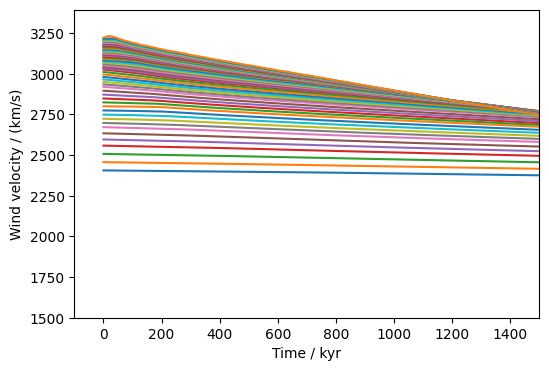

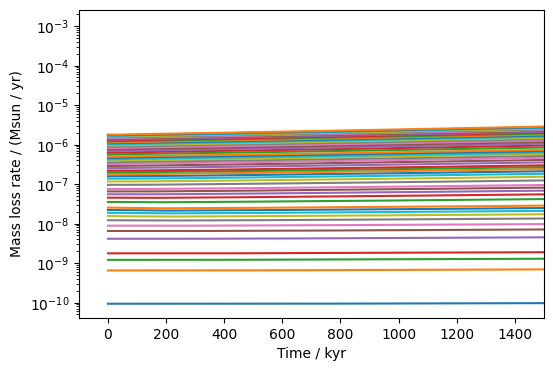

In [7]:
# plot this

# wind velocity
fig, ax = plt.subplots(figsize=(6,4))

for im, mass in enumerate(mass_arr):
    ax.plot(times[im,:].to(u.kyr), vwinds[im,:].to(u.km / u.s), label=f"M = {mass}")
ax.set_xlabel("Time / kyr")
ax.set_ylabel("Wind velocity / (km/s)")
ax.set_xlim(xmin = -100, xmax=1500)
ax.set_ylim(ymin=1500)

# ax.legend(loc="lower left")

# mass loss rate
fig, ax = plt.subplots(figsize=(6,4))

for im, mass in enumerate(mass_arr):
    ax.semilogy(times[im,:].to(u.kyr), Mdots[im,:].to(u.M_sun / u.yr), label=f"M = {mass}")
ax.set_xlabel("Time / kyr")
ax.set_ylabel("Mass loss rate / (Msun / yr)")
ax.set_xlim(xmin = -100, xmax=1500)

# ax.legend(loc="upper left")

Since the wind velocity and mass loss rate are approximately constant within the timeframe of kyrs, can take the time-averge to get the wind velocity and mass loss rate for each mass

Text(0, 0.5, 'Mass loss rate / (Msun / yr)')

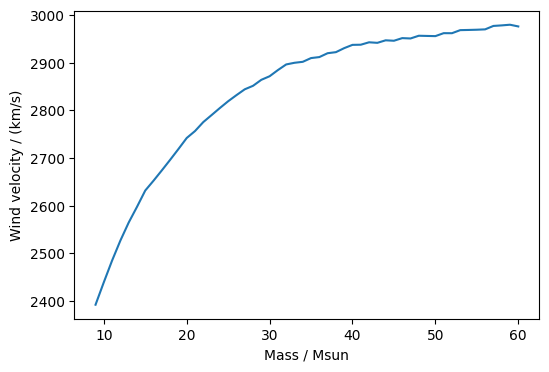

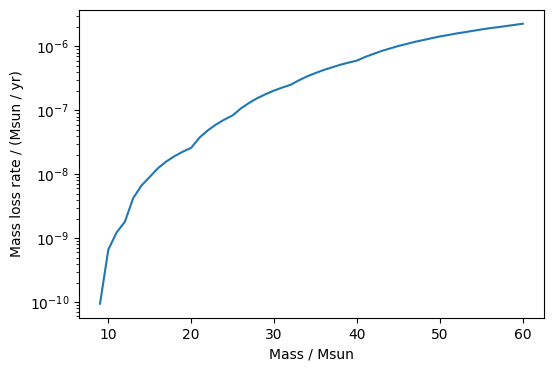

In [8]:
vwinds_mass = np.zeros_like(mass_arr.value) * (u.cm/u.s)
Mdots_mass = np.zeros_like(mass_arr.value) * (u.g/u.s)

for im, mass in enumerate(mass_arr):
    tlim_idx = np.digitize(1500, times[im,:].to_value(u.kyr), right=True)

    vwinds_mass[im] = np.mean(vwinds[im,:tlim_idx])
    Mdots_mass[im] = np.mean(Mdots[im,:tlim_idx])

# wind velocity
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(mass_arr, vwinds_mass.to(u.km/u.s))
ax.set_xlabel("Mass / Msun")
ax.set_ylabel("Wind velocity / (km/s)")

# mass loss rate
fig, ax = plt.subplots(figsize=(6,4))
ax.semilogy(mass_arr, Mdots_mass.to(u.M_sun/u.yr))
ax.set_xlabel("Mass / Msun")
ax.set_ylabel("Mass loss rate / (Msun / yr)")

In [9]:
print((0.5 * Mdots_mass * vwinds_mass**2).to(u.erg / u.s)[np.digitize(20 * u.M_sun, mass_arr, right=True)])
print(np.digitize(20 * u.M_sun, mass_arr, right=True))

6.151412575336804e+34 erg / s
11


Compute the stand-off radius as a function of solar mass and star velocity 

In [10]:
vstar_arr = np.logspace(np.log10(30), np.log10(300), 100) * (u.km / u.s)

Text(0.5, 1.0, 'Stand-off radius for ISM environment')

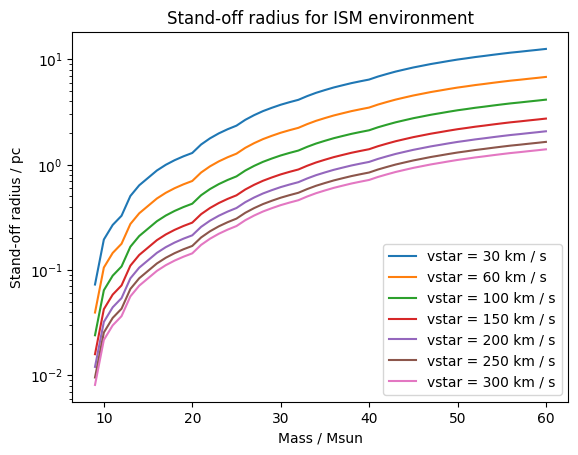

In [11]:
R0_grid = np.zeros((len(mass_arr), len(vstar_arr))) * (u.cm)

for iv, vstar in enumerate(vstar_arr):
    R0_grid[:,iv] = stand_off_radius(Mdots_mass, vwinds_mass, rho0, vstar, P0, adi_idx, B)

# plot for some velocities

fig, ax = plt.subplots()

for iv, vstar in enumerate([30, 60, 100, 150, 200, 250, 300] * (u.km/u.s)):
    vstar_idx = np.digitize(vstar, vstar_arr, right=True)

    ax.semilogy(mass_arr, R0_grid[:,vstar_idx].to(u.pc), label=f"vstar = {vstar:.0f}")

ax.set_xlabel("Mass / Msun")
ax.set_ylabel("Stand-off radius / pc")
ax.legend()
# ax.set_title(f"Stand-off radius for {env} environment")

export this result to .h5 file to access later

In [11]:
with h5py.File("../data/standoff_radius.h5", "w") as f:

    f.create_dataset("mstar_grid", data=mass_arr)
    f.create_dataset("vstar_grid", data=vstar_arr)

    # create for each environment
    env_group = f.create_group(env)
    env_group.create_dataset("B", data=B)
    env_group.create_dataset("rho0", data=rho0)
    env_group.create_dataset("T0", data=T0)
    env_group.create_dataset("P0", data=P0)
    env_group.create_dataset("R0_grid", data=R0_grid)

In [12]:
# # plot a grid
# fig, ax = plt.subplots(figsize=(4,8), layout="constrained")
# extent = [np.min(mass_arr).value, np.max(mass_arr).value, np.min(vstar_arr).value, np.max(vstar_arr).value]
# norm = mcolors.LogNorm(vmin=1e-2, vmax=5, clip=True)

# im = ax.imshow(R0_grid.to_value(u.pc).T, extent=extent, norm=norm, cmap=cm.viridis, interpolation="none")

# # labels
# ax.set_xlabel("Mstar / Msun")
# ax.set_ylabel("vstar / (km/s)")

# cb = fig.colorbar(im, ax=ax)
# cb.ax.set_ylabel("R0 / pc")

Finally we can plot and determniune the minimum mass required for a simulation with some AMR level for some domain size

grid resolution: 0.39 pc
wind injection radius: 3.013357e+18 cm


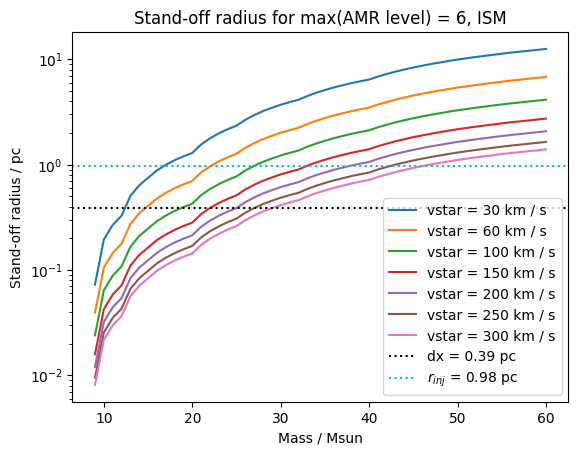

In [13]:
# for Comet-like, we want the bow shock to be ~ 60 pc in size. This means that the bow shock should be 25 pc in width or so

amr_lvl_max = 6  # fortran style

dx = np.abs(xmax - xmin) / (2**(amr_lvl_max - 1) * 8)
print(f"grid resolution: {dx:.2f}")
print(f"wind injection radius: {2.5*dx.to(u.cm):.6e}")

# plot for some velocities

fig, ax = plt.subplots()

for iv, vstar in enumerate([30, 60, 100, 150, 200, 250, 300] * (u.km/u.s)):
    vstar_idx = np.digitize(vstar, vstar_arr, right=True)

    ax.semilogy(mass_arr, R0_grid[:,vstar_idx].to(u.pc), label=f"vstar = {vstar:.0f}")

# now plot grid resolution as a line
ax.axhline(dx.value, label=f"dx = {dx:.2f}", ls=":", color="k")

# also plot the wind injection radius, 2.5 * dx
ax.axhline(2.5 * dx.value, label=f"$r_{{inj}}$ = {2.5 * dx:.2f}", ls=":", color="c")

ax.set_xlabel("Mass / Msun")
ax.set_ylabel("Stand-off radius / pc")
ax.set_title(f"Stand-off radius for max(AMR level) = {amr_lvl_max}, {env}")
ax.legend()

In [14]:
# we can also print this easily for a single vstar

amr_lvls = np.arange(5, 9, 1)  # AMR level 5 to 8, in fortran style
min_mass_arr = np.zeros((len(amr_lvls), len(vstar_arr))) * u.M_sun

for il, amr_lvl in enumerate(amr_lvls):

    # compute dx
    dx = np.abs(xmax - xmin) / (2**(amr_lvl - 1) * 8)

    for iv, vstar in enumerate(vstar_arr):
        min_mass_arr[il, iv] = np.min(mass_arr[R0_grid[:,iv] > 2.5 * dx])

        # print(f"minimum mass required for vstar = {vstar}: {min_mass}")

ValueError: zero-size array to reduction operation minimum which has no identity

(8.0, 50.0)

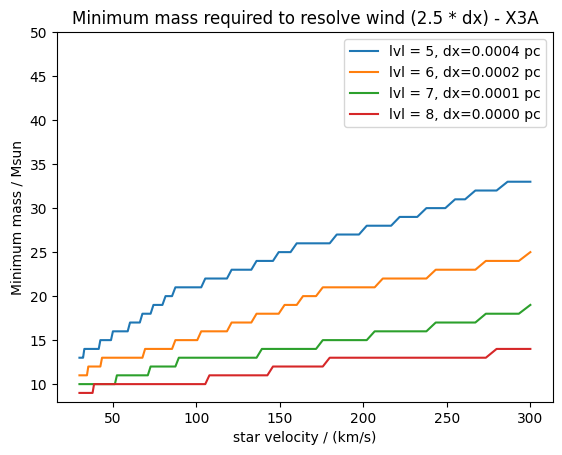

In [ ]:
# plot
fig, ax = plt.subplots()

for il, amr_lvl in enumerate(amr_lvls):
    dx = np.abs(xmax - xmin) / (2**(amr_lvl - 1) * 8)

    ax.plot(vstar_arr, min_mass_arr[il,:], label=f"lvl = {amr_lvl}, dx={dx:.4f}")

ax.set_xlabel("star velocity / (km/s)")
ax.set_ylabel("Minimum mass / Msun")
ax.set_title(f"Minimum mass required to resolve wind (2.5 * dx) - {env}")
ax.legend()
ax.set_ylim(ymin=8, ymax=50)

### Use this array to get it for particular star velocity and amr level

In [ ]:
vstar_sel = 30 * (u.km/u.s)
max_amr_lvl = 8

min_mass_sel = min_mass_arr[np.digitize(max_amr_lvl, amr_lvls, right=True), np.digitize(vstar_sel, vstar_arr, right=True)]

print(f"minimum mass required for vstar of {vstar_sel:.2f} with amr level {max_amr_lvl}: {min_mass_sel}")

minimum mass required for vstar of 30.00 km / s with amr level 8: 9.0 solMass


### Also capture the stand-off radius as a function of the cell size

For a certain mass and velocity

In [ ]:
vstar_sel = 244 * (u.km/u.s)
mass_sel = 15 * (u.M_sun)
max_amr_lvl = 8

# compute dx
dx = np.abs(xmax - xmin) / (2**(max_amr_lvl - 1) * 8)

R0 = R0_grid[np.digitize(mass_sel, mass_arr, right=True), np.digitize(vstar_sel, vstar_arr, right=True)]

print(f"Stand-off radius as a function of dx: {R0.to(u.pc) / dx :4f} dx")
print(f"Stand-off radius as a function of wind injection radius: {R0.to(u.pc) / (2.5 * dx) :4f}")

Stand-off radius as a function of dx: 4.085188 dx
Stand-off radius as a function of wind injection radius: 1.634075
